# Traitement initial des données 


In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("/Users/Sherif//Desktop/Prevision_supermarche/supermarket_sales_forecasting.csv")

print(df.shape)
df.head()

(5500, 16)


,Date,Store_ID,Store_Type,Store_Size,City,Promo,Holiday,School_Holiday,Weekend,Temperature,Rainfall,Fuel_Price,Inflation_Rate,Economic_Index,Competitor_Distance,Sales
0,2023-01-01,S003,B,3500,Parakou,0,0,0,1,27.2,17.2,694.03,4.85,91.4,4.5,11902.52
1,2023-01-01,S010,B,3300,Kandi,0,0,1,1,26.4,18.2,714.18,8.09,96.4,8.0,10822.53
2,2023-01-01,S003,B,3500,Parakou,0,0,0,1,27.9,18.6,669.26,7.71,101.4,4.5,10713.21
3,2023-01-01,S010,B,3300,Kandi,0,0,0,1,28.6,6.3,668.46,6.89,108.2,8.0,10925.09
4,2023-01-01,S008,A,4700,Ouidah,0,0,1,1,28.1,30.5,659.87,7.70,94.3,2.8,13415.18


In [ ]:
#les information sur les variations 
df.info()

In [19]:
# determination des valeurs manquantes
manque= df.isnull().sum().sort_values(ascending=False)
manque[manque > 0].count()
print(df.dtypes)
print(df.duplicated().sum())

Date                   datetime64[ns]
Store_ID                       object
Store_Type                     object
Store_Size                      int64
City                           object
Promo                           int64
Holiday                         int64
School_Holiday                  int64
Weekend                         int64
Temperature                   float64
Rainfall                      float64
Fuel_Price                    float64
Inflation_Rate                float64
Economic_Index                float64
Competitor_Distance           float64
Sales                         float64
dtype: object
0


In [17]:
df.describe()


,Date,Store_Size,Promo,Holiday,School_Holiday,Weekend,Temperature,Rainfall,Fuel_Price,Inflation_Rate,Economic_Index,Competitor_Distance,Sales
count,5500,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000,5500.000000
mean,2024-06-22 12:34:17.890908928,3346.600000,0.302727,0.040000,0.150727,0.277273,29.728982,45.004345,680.132409,5.518195,99.957491,4.332709,9889.984880
min,2023-01-01 00:00:00,2100.000000,0.000000,0.000000,0.000000,0.000000,22.700000,0.000000,604.850000,2.500000,90.000000,1.200000,1507.070000
25%,2023-09-21 00:00:00,2500.000000,0.000000,0.000000,0.000000,0.000000,27.700000,19.700000,666.600000,4.000000,95.000000,2.100000,8009.105000
50%,2024-06-16 12:00:00,3300.000000,0.000000,0.000000,0.000000,0.000000,29.500000,33.900000,680.025000,5.520000,99.900000,4.500000,9807.080000
75%,2025-03-23 00:00:00,4200.000000,1.000000,0.000000,0.000000,1.000000,31.600000,70.100000,693.585000,7.060000,105.000000,6.500000,11590.860000
max,2025-12-31 00:00:00,4700.000000,1.000000,1.000000,1.000000,1.000000,39.200000,120.000000,760.310000,8.500000,110.000000,8.000000,18551.230000
std,NaN,866.554026,0.459480,0.195977,0.357815,0.447693,2.766481,33.631672,20.138989,1.745271,5.790438,2.275250,2588.551058


### structure temporelle

In [ ]:
#conversion des dates
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values(["Store_ID", "Date"])
print(df["Date"])


In [ ]:
#periode de datation
datemin=print(df["Date"].min())
datemax=print(df["Date"].max())

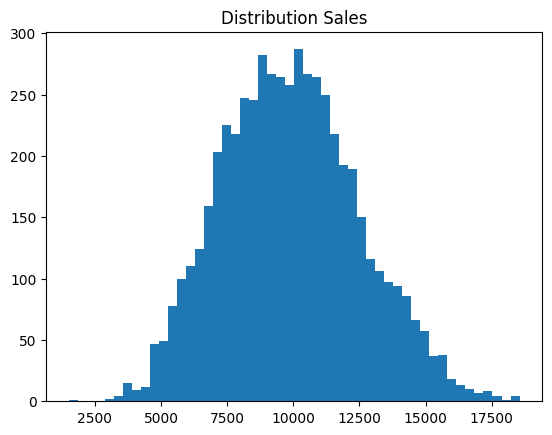

count     5500.000000
mean      9889.984880
std       2588.551058
min       1507.070000
25%       8009.105000
50%       9807.080000
75%      11590.860000
max      18551.230000
Name: Sales, dtype: float64

In [20]:
#analyse de distribution des ventes
plt.hist(df["Sales"], bins=50)
plt.title("Distribution Sales")
plt.show()
#statistisque descriptive sur la variable sales
df["Sales"].describe()

Store_ID
S008    12646.334802
S001    12621.819415
S002    11630.687442
S003    10243.028649
S004     9937.881945
S007     9587.089203
S010     9160.916309
S005     8287.258750
S006     7870.891950
S009     7232.940036
Name: Sales, dtype: float64


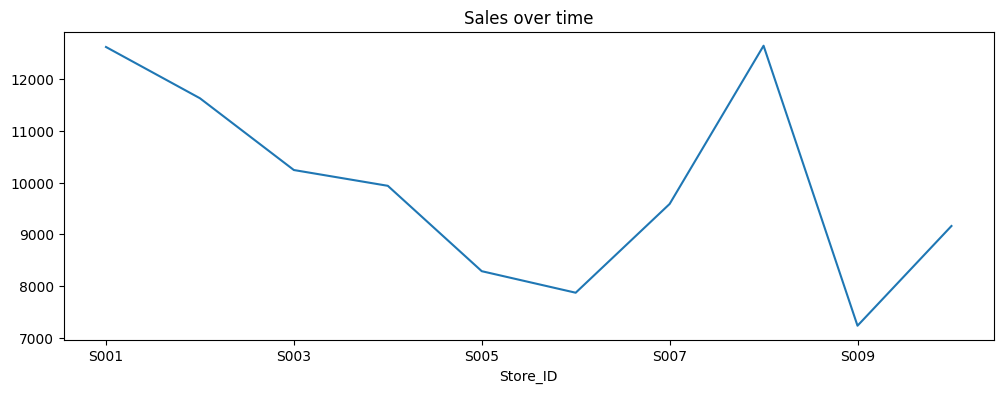

In [25]:
#impact des magasins sur les ventes
impact_mag =df.groupby("Store_ID")["Sales"].mean().sort_values(ascending=False).head(10)
print(impact_mag)
df.groupby("Store_ID")["Sales"].mean().plot(figsize=(12,4))
plt.title("Sales over time")
plt.show()

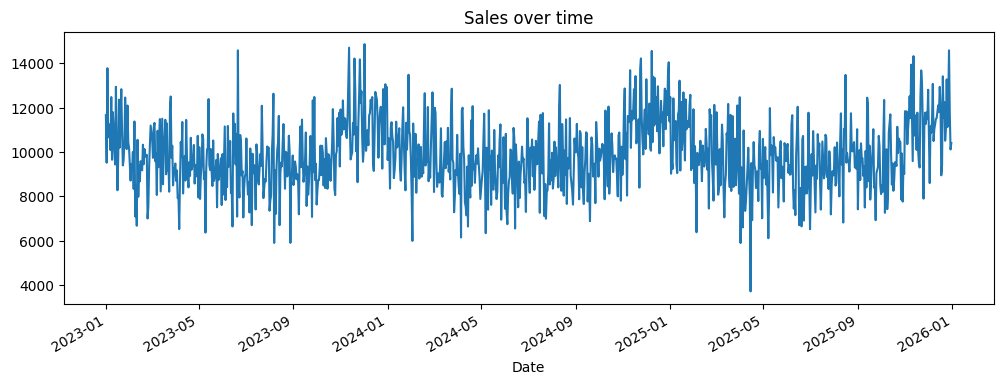

In [22]:
#impact de la date sur les ventes
df.groupby("Date")["Sales"].mean().plot(figsize=(12,4))
plt.title("ventes par date")
plt.show()

In [27]:
#impact de la var promotion sur les ventes
df.groupby("Promo")["Sales"].mean()

Promo
0     9120.024368
1    11663.437471
Name: Sales, dtype: float64

In [28]:
#impact de la var fériée  sur les ventes
df.groupby("Holiday")["Sales"].mean()


Holiday
0     9818.734960
1    11599.982955
Name: Sales, dtype: float64

In [29]:
#impact de la var weekend  sur les ventes
df.groupby("Weekend")["Sales"].mean()

Weekend
0     9554.148893
1    10765.360649
Name: Sales, dtype: float64

In [30]:
#impact de la var type du magasin  sur les ventes
df.groupby("Store_Type")["Sales"].mean().sort_values()

Store_Type
C     7803.569744
B     9718.173333
A    12309.392223
Name: Sales, dtype: float64

In [34]:
#impact de la var ville sur les ventes
df.groupby("City")["Sales"].mean().sort_values().head(10)

City
Djougou           7232.940036
Lokossa           7870.891950
Bohicon           8287.258750
Kandi             9160.916309
Natitingou        9587.089203
Abomey-Calavi     9937.881945
Parakou          10243.028649
Porto-Novo       11630.687442
Cotonou          12621.819415
Ouidah           12646.334802
Name: Sales, dtype: float64

## etude de correlation

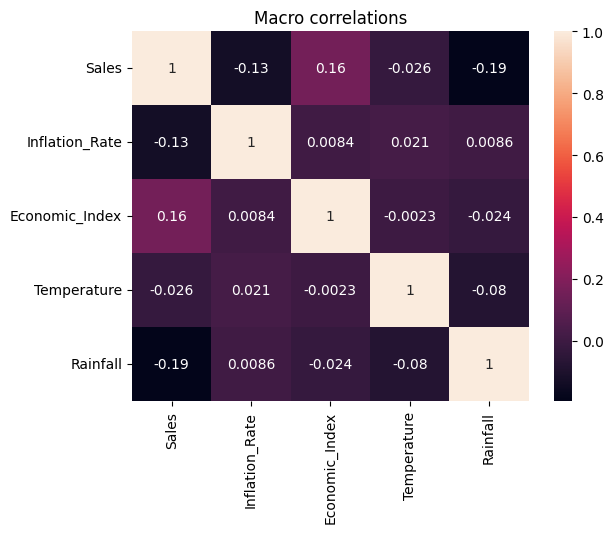

In [35]:
#determination des correlations macroéconomiques
corr = df[["Sales","Inflation_Rate","Economic_Index","Temperature","Rainfall"]].corr()

sns.heatmap(corr, annot=True)
plt.title("Macro correlations")
plt.show()

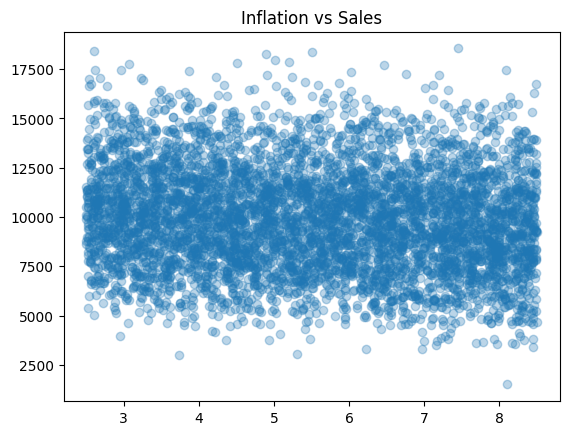

In [36]:
#test non_lineaire entre l'infaction et les ventes
plt.scatter(df["Inflation_Rate"], df["Sales"], alpha=0.3)
plt.title("Inflation vs Sales")
plt.show()

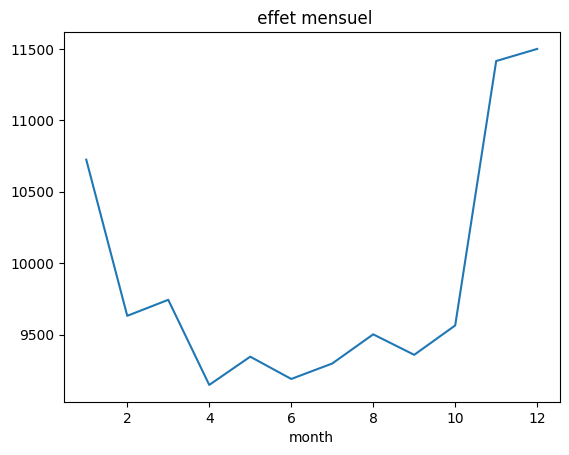

In [40]:
#effet du mois
df["Date"] = pd.to_datetime(df["Date"])
df["month"] = df["Date"].dt.month
df["day_of_week"] = df["Date"].dt.dayofweek
df.groupby("month")["Sales"].mean().plot()
plt.title(" effet mensuel")
plt.show()

In [46]:
#classement des variables expliquants les ventes
numeric_df = df.select_dtypes(include=np.number)
corr_matrix = numeric_df.corr()
corr_matrix["Sales"].sort_values(ascending=False)

Sales                  1.000000
Store_Size             0.684423
Promo                  0.451468
Weekend                0.209481
day_of_week            0.170846
Economic_Index         0.155747
Holiday                0.134857
School_Holiday         0.113845
month                  0.111741
Temperature           -0.026399
Fuel_Price            -0.099078
Inflation_Rate        -0.129761
Rainfall              -0.194957
Competitor_Distance   -0.474550
Name: Sales, dtype: float64

In [ ]:
#test des interactions

In [43]:
#interaction entre les var promotion et week-ends 
df.groupby(["Promo","Weekend"])["Sales"].mean()

Promo  Weekend
0      0           8803.282228
       1           9962.352939
1      0          11315.651751
       1          12529.620776
Name: Sales, dtype: float64

In [44]:
#interaction entre les var promotion et type de mag
df.groupby(["Promo","Store_Type"])["Sales"].mean()

Promo  Store_Type
0      A             11506.937121
       B              8951.773465
       C              7057.071641
1      A             14208.704193
       B             11410.917391
       C              9575.378494
Name: Sales, dtype: float64

In [45]:
#variance de structure
store_variance = df.groupby("Store_ID")["Sales"].var().sort_values()
store_variance.head()

Store_ID
S005    3.036318e+06
S010    3.114031e+06
S004    3.164750e+06
S006    3.310107e+06
S002    3.323440e+06
Name: Sales, dtype: float64

In [52]:
print(df.info())
print()
print(df.describe())
print()
print(df.groupby("Promo")["Sales"].mean())
print()
print(df.groupby("Holiday")["Sales"].mean())
print()
print(df.groupby("Weekend")["Sales"].mean())
print()
print(df.groupby("Store_Type")["Sales"].mean())
print()
numeric_df = df.select_dtypes(include="number")
print()
print(numeric_df.corr()["Sales"].sort_values(ascending=False))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5500 entries, 0 to 5499
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Date                 5500 non-null   datetime64[ns]
 1   Store_ID             5500 non-null   object        
 2   Store_Type           5500 non-null   object        
 3   Store_Size           5500 non-null   int64         
 4   City                 5500 non-null   object        
 5   Promo                5500 non-null   int64         
 6   Holiday              5500 non-null   int64         
 7   School_Holiday       5500 non-null   int64         
 8   Weekend              5500 non-null   int64         
 9   Temperature          5500 non-null   float64       
 10  Rainfall             5500 non-null   float64       
 11  Fuel_Price           5500 non-null   float64       
 12  Inflation_Rate       5500 non-null   float64       
 13  Economic_Index       5500 non-nul